<a href="https://colab.research.google.com/github/meliaaputr9/Preprocessing-Raw-Data/blob/main/Preprocessing_Data_Temperatur_Amelia_Putri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Import Library & Loading Raw Data**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Set styling visualisasi
sns.set_theme(style="whitegrid")

# Dataset observasi iklim harian riil
url_weather = "https://raw.githubusercontent.com/plotly/datasets/master/2016-weather-data-seattle.csv"
df_raw = pd.read_csv(url_weather)

# Menampilkan 5 baris pertama data mentah
df_raw.head()

,Date,Max_TemperatureC,Mean_TemperatureC,Min_TemperatureC
0,1/1/1948,10,8.0,7.0
1,1/2/1948,6,4.0,3.0
2,1/3/1948,7,4.0,2.0
3,1/4/1948,7,4.0,2.0
4,1/5/1948,7,3.0,0.0


**Ringkasan Dataset**

In [ ]:
# Cek Ukuran Data (Baris, Kolom)
print(f"Jumlah Baris: {df_raw.shape[0]} | Jumlah Kolom: {df_raw.shape[1]}\n")

# Tabel Ringkasan Variabel & Jumlah Data Terisi
df_info = pd.DataFrame({
    'Tipe Data': df_raw.dtypes,
    'Jumlah Terisi (Non-Null)': df_raw.count(),
    'Jumlah Kosong (Null)': df_raw.isnull().sum()
})

df_info

Jumlah Baris: 24381 | Jumlah Kolom: 4



,Tipe Data,Jumlah Terisi (Non-Null),Jumlah Kosong (Null)
Date,object,24381,0
Max_TemperatureC,int64,24381,0
Mean_TemperatureC,float64,24376,5
Min_TemperatureC,float64,24380,1


**Diagnostik Missing Values & Identifikasi Tipe Data**

In [ ]:
# Analisis ringkasan missing values dan tipe data
missing_summary = pd.DataFrame({
    'Tipe Data': df_raw.dtypes,
    'Jumlah Missing': df_raw.isnull().sum(),
    'Persentase Missing (%)': (df_raw.isnull().sum() / len(df_raw)) * 100
})

missing_summary

,Tipe Data,Jumlah Missing,Persentase Missing (%)
Date,object,0,0.000000
Max_TemperatureC,int64,0,0.000000
Mean_TemperatureC,float64,5,0.020508
Min_TemperatureC,float64,1,0.004102


**Visualisasi Diagnostik Awal**

Visualisasi awal ini bertujuan untuk melihat sebaran nilai suhu mentah (Mean_TemperatureF, Max_TemperatureF, Min_TemperatureF) serta mengidentifikasi keberadaan outlier dan celah data kosong sebelum dibersihkan.

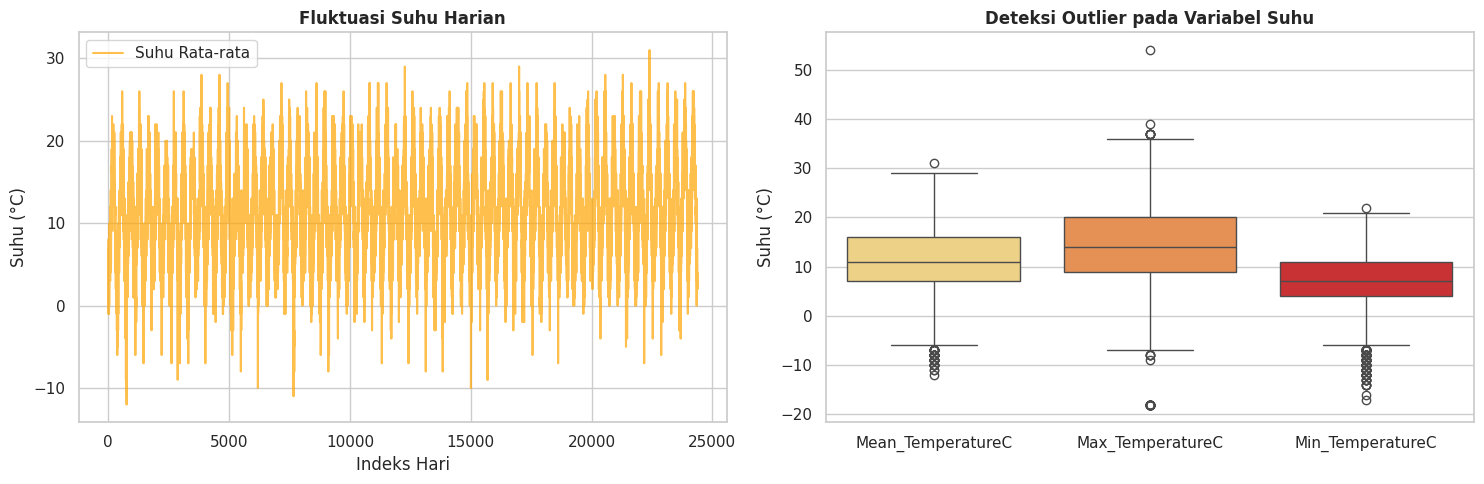

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Tren Suhu Harian
axes[0].plot(df_raw.index, df_raw['Mean_TemperatureC'], color='orange', alpha=0.7, label='Suhu Rata-rata')
axes[0].set_title("Fluktuasi Suhu Harian", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Indeks Hari")
axes[0].set_ylabel("Suhu (°C)")
axes[0].legend()

# Boxplot Deteksi Outlier Suhu & Kelembapan
sns.boxplot(data=df_raw[['Mean_TemperatureC', 'Max_TemperatureC', 'Min_TemperatureC']], ax=axes[1], palette="YlOrRd")
axes[1].set_title("Deteksi Outlier pada Variabel Suhu", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Suhu (°C)")

plt.tight_layout()
plt.show()

**Parsing Format Tanggal (Datetime Conversion) & Feature Engineering**

Kolom Date pada data mentah diubah dari tipe string/object menjadi datetime64. Selanjutnya, dilakukan feature engineering untuk mengekstrak komponen waktu baru seperti Month (Bulan) dan Day (Hari) yang bermanfaat untuk analisis musiman.

In [ ]:
df_processed = df_raw.copy()

# Konversi ke format datetime
df_processed['Date'] = pd.to_datetime(df_processed['Date'])

# Ekstraksi fitur temporal
df_processed['Month'] = df_processed['Date'].dt.month
df_processed['Day'] = df_processed['Date'].dt.day
df_processed['DayOfWeek'] = df_processed['Date'].dt.day_name()

# Output 5 baris hasil ekstraksi fitur baru
df_processed[['Date', 'Month', 'Day', 'DayOfWeek', 'Mean_TemperatureC']].head()

,Date,Month,Day,DayOfWeek,Mean_TemperatureC
0,1948-01-01,1,1,Thursday,8.0
1,1948-01-02,1,2,Friday,4.0
2,1948-01-03,1,3,Saturday,4.0
3,1948-01-04,1,4,Sunday,4.0
4,1948-01-05,1,5,Monday,3.0


**Handling Missing Values (Time-Series Linear Interpolation)**

Untuk data observasi cuaca/harian, penghapusan baris kosong (drop rows) tidak disarankan karena merusak deret waktu. Kita menggunakan metode Interpolasi Linear untuk mengisi nilai yang hilang secara halus berdasarkan tren hari sebelum dan sesudahnya.

In [ ]:
temp_cols = ['Mean_TemperatureC', 'Max_TemperatureC', 'Min_TemperatureC']

# Imputasi data kosong dengan interpolasi linear
df_processed[temp_cols] = df_processed[temp_cols].interpolate(method='linear')

# Verifikasi bahwa sisa missing values sudah 0
df_processed[temp_cols].isnull().sum().to_frame(name='Sisa Missing Value')

,Sisa Missing Value
Mean_TemperatureC,0
Max_TemperatureC,0
Min_TemperatureC,0


**Deteksi & Treatment Outliers (Winsorization / Capping via IQR)**

Untuk menangani nilai ekstrem pada suhu tanpa membuang baris data, diterapkan pembatasan (capping) menggunakan metode Interquartile Range (IQR). Nilai di luar rentang $[Q1 - 1.5 \times IQR, Q3 + 1.5 \times IQR]$ akan dibatasi (clip) ke ambang batas terdekat.

In [ ]:
# Menghitung IQR untuk Mean_TemperatureF
Q1 = df_processed['Mean_TemperatureC'].quantile(0.25)
Q3 = df_processed['Mean_TemperatureC'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Capping outlier
df_processed['Mean_TemperatureF_Capped'] = np.clip(df_processed['Mean_TemperatureC'], lower_bound, upper_bound)

# Tampilkan batas toleransi IQR
print(f"Batas Bawah Toleransi IQR: {lower_bound:.2f} °C")
print(f"Batas Atas Toleransi IQR: {upper_bound:.2f} °C")

Batas Bawah Toleransi IQR: -6.50 °C
Batas Atas Toleransi IQR: 29.50 °C


**Feature Scaling (Z-Score Standardization)**

Langkah ini mentransformasikan variabel numerik suhu menggunakan StandardScaler agar memiliki rata-rata $\mu = 0$ dan standar deviasi $\sigma = 1$. Hal ini penting agar variansi antar fitur seimbang saat masuk ke algoritma pemodelan/analisis lanjut.

In [ ]:
scaler = StandardScaler()

# Scaling variabel numerik
df_scaled = df_processed.copy()
df_scaled[temp_cols] = scaler.fit_transform(df_processed[temp_cols])

# Ringkasan statistik deskriptif setelah scaling (Mean ≈ 0, Std ≈ 1)
df_scaled[temp_cols].describe().round(3)

,Mean_TemperatureC,Max_TemperatureC,Min_TemperatureC
count,24381.000,24381.000,24381.000
mean,0.000,-0.000,-0.000
std,1.000,1.000,1.000
min,-3.978,-4.594,-4.936
25%,-0.698,-0.829,-0.662
50%,-0.008,-0.132,-0.051
75%,0.855,0.705,0.763
max,3.445,5.446,3.001


**Evaluasi Akhir & Visualisasi Komparatif (Post-Cleaning Analysis)**

Tahap akhir membandingkan kondisi distribusi data sebelum (Raw Data) dan sesudah (Preprocessed & Scaled Data). Visualisasi membuktikan bahwa data kini penuh (no NaN), memiliki skala yang seragam, dan siap digunakan.

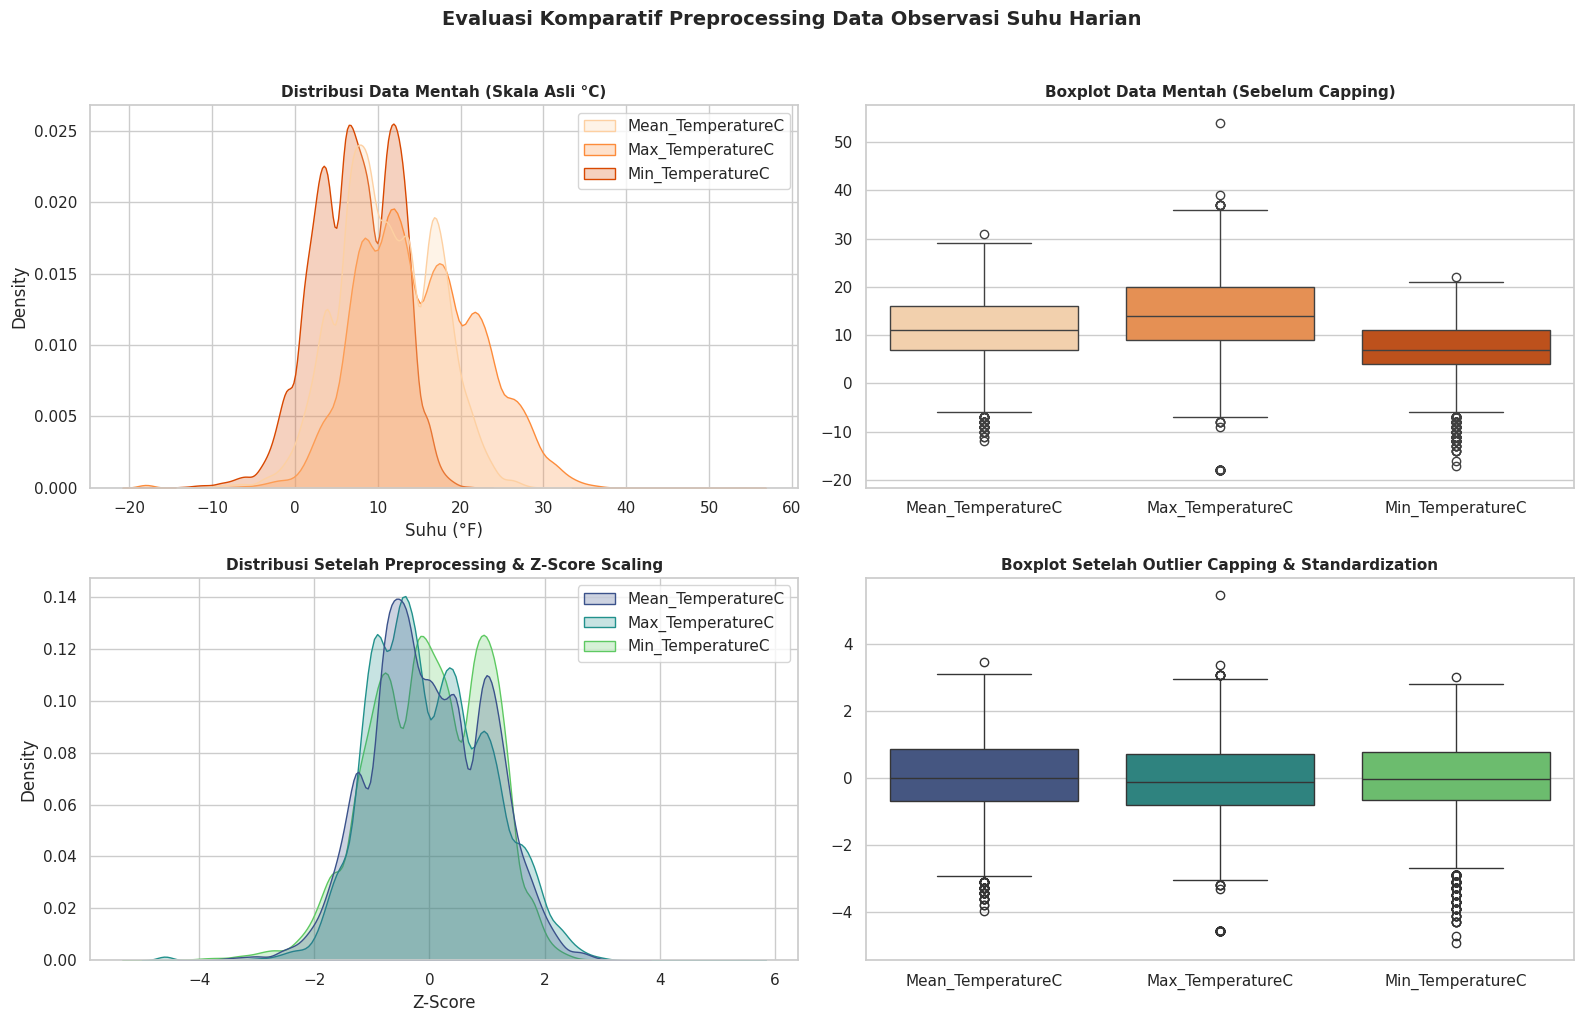

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Distribusi Mentah (Before)
sns.kdeplot(data=df_raw[temp_cols], ax=axes[0, 0], fill=True, palette="Oranges")
axes[0, 0].set_title("Distribusi Data Mentah (Skala Asli °C)", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel("Suhu (°F)")

# Boxplot Mentah (Before)
sns.boxplot(data=df_raw[temp_cols], ax=axes[0, 1], palette="Oranges")
axes[0, 1].set_title("Boxplot Data Mentah (Sebelum Capping)", fontsize=11, fontweight='bold')

# Distribusi Scaled (After)
sns.kdeplot(data=df_scaled[temp_cols], ax=axes[1, 0], fill=True, palette="viridis")
axes[1, 0].set_title("Distribusi Setelah Preprocessing & Z-Score Scaling", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("Z-Score")

# Boxplot Scaled (After)
sns.boxplot(data=df_scaled[temp_cols], ax=axes[1, 1], palette="viridis")
axes[1, 1].set_title("Boxplot Setelah Outlier Capping & Standardization", fontsize=11, fontweight='bold')

plt.suptitle("Evaluasi Komparatif Preprocessing Data Observasi Suhu Harian", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()